# Clasificación de Fashion-MNIST - PyTorch

Notebook principal de la clase: red densa con validación, dropout, detención temprana y análisis por clase.

## Dependencias

En un entorno nuevo: `%pip install torch torchvision numpy matplotlib scikit-learn`. La primera carga de Fashion-MNIST descarga el dataset.

Este notebook debe ejecutarse con el kernel **Python 3 (IPD434)**. Para usar GPU, instala la variante de PyTorch compatible con tu sistema desde el selector oficial; el código detecta automáticamente CPU o CUDA.

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Dispositivo:', device)

PyTorch: 2.11.0+cu128
Dispositivo: cuda


In [2]:
DATA_ROOT = Path('../data/fashion_mnist')
to_tensor = transforms.ToTensor()

train_full = datasets.FashionMNIST(
    root=DATA_ROOT, train=True, download=True, transform=to_tensor
)
test_set = datasets.FashionMNIST(
    root=DATA_ROOT, train=False, download=True, transform=to_tensor
)

# Mantener la misma lógica de partición que en el notebook TensorFlow.
n_val = 6000
train_set = Subset(train_full, range(0, len(train_full) - n_val))
val_set = Subset(train_full, range(len(train_full) - n_val, len(train_full)))

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True, generator=loader_generator, num_workers=0)
val_loader = DataLoader(val_set, batch_size=256, shuffle=False, num_workers=0)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=0)

print('Entrenamiento:', len(train_set))
print('Validación:', len(val_set))
print('Prueba:', len(test_set))

100.0%

Entrenamiento: 54000
Validación: 6000
Prueba: 10000


La prueba queda aislada. El escalamiento se realiza al convertir las imágenes a tensores, y la partición de validación se usa durante el ajuste, no para reportar el desempeño final.

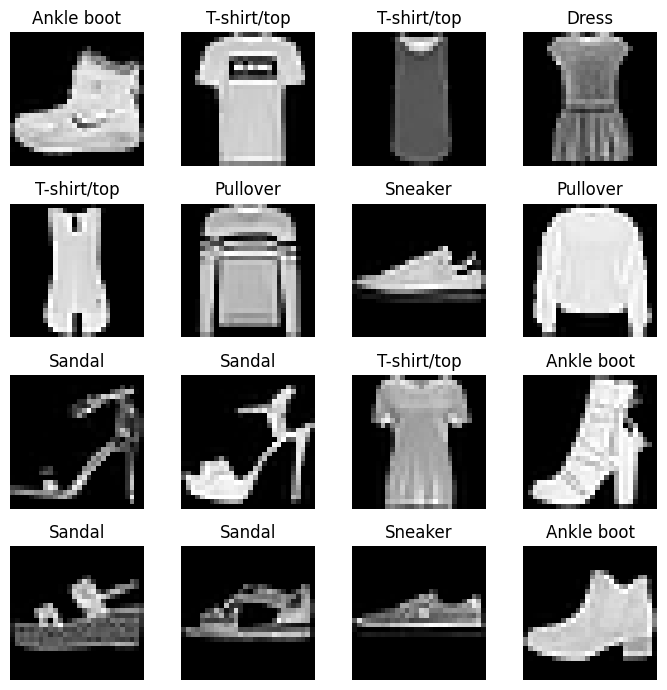

In [3]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

images, labels = next(iter(DataLoader(train_set, batch_size=16, shuffle=False)))
fig, axes = plt.subplots(4, 4, figsize=(7, 7))
for ax, image, label in zip(axes.ravel(), images, labels):
    ax.imshow(image.squeeze(), cmap='gray')
    ax.set_title(class_names[label.item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [4]:
class FashionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.network(x)

model = FashionMLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(model)
print('Parámetros entrenables:', sum(p.numel() for p in model.parameters() if p.requires_grad))

# CrossEntropyLoss recibe logits; no agregamos softmax dentro del modelo.

FashionMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parámetros entrenables: 101770


## Entrenamiento explícito

PyTorch hace visible el ciclo de aprendizaje: `model.train()`, gradiente con `loss.backward()` y actualización con `optimizer.step()`. En validación se usa `model.eval()` y se desactivan los gradientes.

In [5]:
def run_epoch(model, loader, criterion, device, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
        else:
            with torch.no_grad():
                logits = model(images)
                loss = criterion(logits, labels)

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

max_epochs = 30
patience = 3
best_val_loss = float('inf')
best_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0
history = {'train_loss': [], 'val_loss': [], 'train_accuracy': [], 'val_accuracy': []}

for epoch in range(1, max_epochs + 1):
    train_loss, train_accuracy = run_epoch(model, train_loader, criterion, device, optimizer)
    val_loss, val_accuracy = run_epoch(model, val_loader, criterion, device)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_accuracy'].append(train_accuracy)
    history['val_accuracy'].append(val_accuracy)

    print(
        f'Epoch {epoch:02d}: '
        f'train_loss={train_loss:.4f}, val_loss={val_loss:.4f}, '
        f'train_acc={train_accuracy:.3f}, val_acc={val_accuracy:.3f}'
    )

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print('Detención temprana.')
            break

model.load_state_dict(best_state)

Epoch 01: train_loss=0.6523, val_loss=0.4520, train_acc=0.776, val_acc=0.836
Epoch 02: train_loss=0.4481, val_loss=0.4038, train_acc=0.841, val_acc=0.853
Epoch 03: train_loss=0.4053, val_loss=0.3739, train_acc=0.856, val_acc=0.866
Epoch 04: train_loss=0.3759, val_loss=0.3536, train_acc=0.866, val_acc=0.872
Epoch 05: train_loss=0.3610, val_loss=0.3460, train_acc=0.869, val_acc=0.879
Epoch 06: train_loss=0.3454, val_loss=0.3485, train_acc=0.874, val_acc=0.875
Epoch 07: train_loss=0.3319, val_loss=0.3368, train_acc=0.879, val_acc=0.880
Epoch 08: train_loss=0.3232, val_loss=0.3299, train_acc=0.883, val_acc=0.881
Epoch 09: train_loss=0.3130, val_loss=0.3358, train_acc=0.885, val_acc=0.873
Epoch 10: train_loss=0.3080, val_loss=0.3255, train_acc=0.888, val_acc=0.884
Epoch 11: train_loss=0.3008, val_loss=0.3344, train_acc=0.889, val_acc=0.875
Epoch 12: train_loss=0.2939, val_loss=0.3163, train_acc=0.892, val_acc=0.881
Epoch 13: train_loss=0.2875, val_loss=0.3160, train_acc=0.894, val_acc=0.884

<All keys matched successfully>

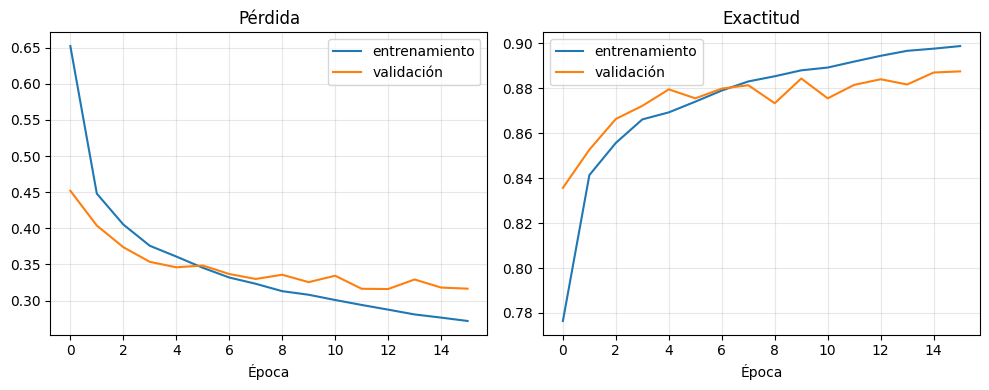

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history['train_loss'], label='entrenamiento')
axes[0].plot(history['val_loss'], label='validación')
axes[0].set(title='Pérdida', xlabel='Época')
axes[1].plot(history['train_accuracy'], label='entrenamiento')
axes[1].plot(history['val_accuracy'], label='validación')
axes[1].set(title='Exactitud', xlabel='Época')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Evaluación final

La prueba se usa después de fijar arquitectura, optimizador y punto de detención. Las predicciones se obtienen a partir de los logits mediante `argmax`; no es necesario calcular `softmax` para decidir la clase.

In [7]:
def predict_all(model, loader, device):
    model.eval()
    logits_all, labels_all = [], []
    with torch.no_grad():
        for images, labels in loader:
            logits_all.append(model(images.to(device)).cpu())
            labels_all.append(labels)
    return torch.cat(logits_all).numpy(), torch.cat(labels_all).numpy()

test_logits, y_test = predict_all(model, test_loader, device)
y_pred = test_logits.argmax(axis=1)
test_accuracy = (y_pred == y_test).mean()

print(f'accuracy={test_accuracy:.4f}')
print(classification_report(y_test, y_pred, target_names=class_names, digits=3, zero_division=0))

accuracy=0.8775
              precision    recall  f1-score   support

 T-shirt/top      0.820     0.847     0.833      1000
     Trouser      0.995     0.962     0.978      1000
    Pullover      0.823     0.735     0.777      1000
       Dress      0.866     0.901     0.883      1000
        Coat      0.755     0.840     0.795      1000
      Sandal      0.975     0.947     0.961      1000
       Shirt      0.707     0.658     0.682      1000
     Sneaker      0.945     0.935     0.940      1000
         Bag      0.958     0.979     0.968      1000
  Ankle boot      0.932     0.971     0.951      1000

    accuracy                          0.877     10000
   macro avg      0.878     0.878     0.877     10000
weighted avg      0.878     0.877     0.877     10000



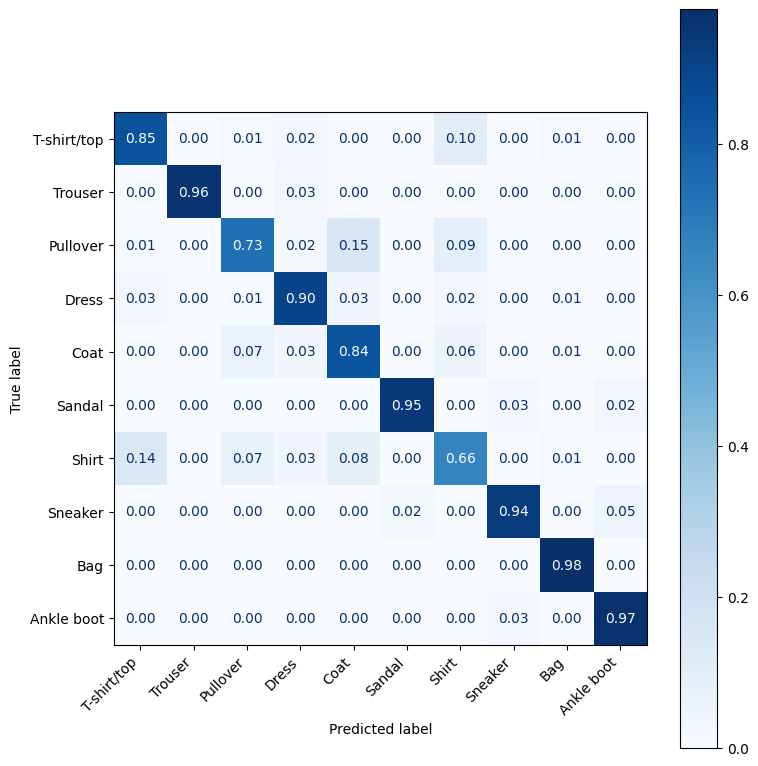

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names,
    normalize='true', values_format='.2f', cmap='Blues', ax=ax
)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()